# ПРАКТИКУМ ПО МАШИННОМУ ОБУЧЕНИЮ: КОД И АЛГОРИТМ KNN
**Темы:** Предобработка данных, Категориальное кодирование, Нормализация, Алгоритм К ближайших соседей (KNN), Подбор гиперпараметров, Метрики расстояний, Intel® Extension for Scikit-learn и Борьба с переобучением.

### Упражнение 1: Инженерия признаков и удаление нерелевантных колонок
В наборе данных Orange Telecom Churn колонки `state`, `area_code` и `phone_number` были удалены в ноутбуке. Напишите блок кода на Pandas, который анализирует уникальную кардинальность каждой оставшейся и удаленной категориальной колонки. Объясните с математической точки зрения, почему применение `OneHotEncoder` или `LabelBinarizer` к колонке со сотнями уникальных значений (например, `phone_number`) разрушит пространственную эффективность и вызовет высокий риск переобучения для алгоритма KNN.

In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('./data/Orange_Telecom_Churn_Data.csv')

print('Строк:', len(df))

print('Удаленные колонки:')
print(df[['state', 'area_code', 'phone_number']].nunique())

print('Оставшиеся колонки:')
print(df[['intl_plan', 'voice_mail_plan']].nunique())

df = df.drop(columns=['state', 'area_code', 'phone_number'])

Строк: 5000
Удаленные колонки:
state             51
area_code          3
phone_number    5000
dtype: int64
Оставшиеся колонки:
intl_plan          2
voice_mail_plan    2
dtype: int64


**Объяснение** Номер телефона имеет разные значения, их столько сколько строк в наборе данных, если сделать OneHot то получится много столбцов и расстояние между двумя разными номерами будет одинаковым. Номер это просто имя клиента и данный признак ничего не говорит про клиента, поэтому его удаляют потому что модель начнет запоминать людей и переобучатся.

### Упражнение 2: Влияние масштабирования данных на евклидово расстояние
С помощью `MinMaxScaler` все числовые признаки приводятся к диапазону [0, 1]. Предположим, у нас есть два признака: `account_length` (значения от 1 до 250) и `total_day_charge` (значения от 0 до 100). Рассчитайте вручную или напишите код, показывающий, как евклидово расстояние между двумя клиентами искажается, если не применять масштабирование. Что произойдет, если использовать `StandardScaler` вместо `MinMaxScaler`, когда в распределении данных присутствуют выбросы (outliers)?

In [72]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler


clients = np.array([[10, 50],[110, 10]])
borders = np.array([[1, 0], [250, 100]])

print('Без масштабирования:', np.sqrt(np.sum((clients[0] - clients[1])**2)))

minMax = MinMaxScaler().fit(borders).transform(clients)
print('MinMax:', np.sqrt(np.sum((minMax[0] - minMax[1])**2)))

scaler = StandardScaler().fit(borders).transform(clients)
print('StandardScaler:', np.sqrt(np.sum((scaler[0] - scaler[1])**2)))

X_out = np.vstack([borders, [120, 1000]])
scalerWithOutliers = StandardScaler().fit(X_out).transform(clients)
print('Standard с выбросом:', np.sqrt(np.sum((scalerWithOutliers[0] - scalerWithOutliers[1])**2)))


Без масштабирования: 107.70329614269008
MinMax: 0.5668224776469152
StandardScaler: 1.1336449552938304
Standard с выбросом: 0.9874255880453047


**Объяснение:** StandardScaler чувствителен к выбросам, поскольку они смещают среднее и увеличивают стандартное отклонение, из-за чего обычные значения сжимаются около нуля. Для данных с выбросами лучше использовать RobustScaler, который опирается на медиану и межквартильный размах.

### Упражнение 3: Аппаратная оптимизация с Intel® Extension for Scikit-learn
В ноутбуке активировано расширение `from sklearnex import patch_sklearn; patch_sklearn()`. Объясните, как эта библиотека ускоряет операции поиска ближайших соседей (например, с использованием индексированных структур данных, таких как KD-Tree или Ball-Tree, оптимизированных с помощью инструкций AVX-512). Напишите фрагмент кода, измеряющий время выполнения (`timeit`) для обучения `KNeighborsClassifier` с патчем Intel и без него на синтетическом наборе из 100 000 объектов.

In [ ]:
import time
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearnex import patch_sklearn

# Создание синтетических данных
X = np.random.rand(100000, 10)
y = np.random.randint(0, 2, 100000)
X_test = np.random.rand(100000, 10)

model = KNeighborsClassifier(n_neighbors=5)
start = time.time()
model.fit(X, y)
fit_time = time.time() - start
start = time.time()
model.predict(X_test)
predict_time = time.time() - start
print('Без патча: fit =', round(fit_time, 3), 'сек, predict =', round(predict_time, 3), 'сек')


patch_sklearn()

model = KNeighborsClassifier(n_neighbors=5)
start = time.time()
model.fit(X, y)
fit_time = time.time() - start
start = time.time()
model.predict(X_test)
predict_time = time.time() - start
print('С патчем: fit =', round(fit_time, 3), 'сек, predict =', round(predict_time, 3), 'сек')


Без патча: fit = 0.027 сек, predict = 0.573 сек


Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


С патчем: fit = 0.019 сек, predict = 0.578 сек


**Объяснение:** Intel подменяет алгоритмы sklearn на оптимизированные версии. Они используют все ядра процессора, Основная работа у KNN происходит в `predict`, а не в `fit`, поэтому замеряем оба.

### Упражнение 4: Математический анализ метрик расстояния (Минковского, Манхэттенского, Евклидова)
Реализуйте с нуля функцию Python, вычисляющую расстояние Минковского между двумя точками $x$ и $y$ для произвольной степени $p \ge 1$. Продемонстрируйте кодом, как изменение параметра `p` от 1 (Манхэттен) до 2 (Евклидово) и до больших значений ($p \to \infty$, расстояние Чебышева) влияет на границы принятия решений классификатора KNN на двумерном бинарном наборе данных.

In [74]:

from sklearn.datasets import make_moons
from sklearn.neighbors import KNeighborsClassifier

def minkowski_distance(x, y, p):
    return np.sum(np.abs(x - y) ** p) ** (1 / p)

x = np.array([0.0, 0.0])
y = np.array([3.0, 4.0])
print('p=1 (Манхэттен):', minkowski_distance(x, y, 1))
print('p=2 (Евклид):', minkowski_distance(x, y, 2))
print('p=100 (почти Чебышев):', minkowski_distance(x, y, 100))
print('Чебышев (максимум разности):', np.max(np.abs(x - y)))


X_m, y_m = make_moons(n_samples=300, noise=0.3, random_state=1)

xx, yy = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2.5, 200))
grid = np.c_[xx.ravel(), yy.ravel()]


for i, p in enumerate([1, 2, 100]):
    knn = KNeighborsClassifier(n_neighbors=15, p=p)
    knn.fit(X_m, y_m)
    zz = knn.predict(grid).reshape(xx.shape)


p=1 (Манхэттен): 7.0
p=2 (Евклид): 5.0
p=100 (почти Чебышев): 4.000000000000013
Чебышев (максимум разности): 4.0


**Объяснение:** При p=1 расстояние это сумма модулей разностей (3+4=7), при p=2 обычное евклидово (5), при больших p расстояние стремится к максимальной разности по одной координате (4, расстояние Чебышева). На графиках видно, что форма границы между классами зависит от p: при p=1 она более угловатая, при p=2 более гладкая, при большом p определяется только самой большой разностью по одной оси.

### Упражнение 5: Парадокс 100% точности при K=3 на обучающей выборке
Как отмечалось в вопросе 5 ноутбука, запуск KNN с параметром `weights='distance'` или $K=1$ на полном наборе данных (без разделения train/test) дает точность 1.0 (100%). Подробно объясните феномен запоминания (экстремального переобучения) в KNN. Что происходит с ближайшим соседом точки $x_i$, если обучающая выборка включает саму точку $x_i$?

In [ ]:
from sklearn.model_selection import train_test_split

df2 = df.copy()
df2['intl_plan'] = (df2['intl_plan'] == 'yes').astype(int)
df2['voice_mail_plan'] = (df2['voice_mail_plan'] == 'yes').astype(int)

y_all = df2['churned'].astype(int)
X_all = df2.drop(columns=['churned'])

X_scaled = MinMaxScaler().fit_transform(X_all)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_all.values, test_size=0.3, random_state=42, stratify=y_all)

print('Признаков:', X_scaled.shape[1])
print('Доля ушедших клиентов:', round(y_all.mean(), 3))

knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X_scaled, y_all)
print('K=1, оценка на обучающих данных:', knn.score(X_scaled, y_all))

knn2 = KNeighborsClassifier(n_neighbors=2).fit(X_scaled, y_all)
dist, idx = knn2.kneighbors(X_scaled[:3])
print('Индексы ближайших соседей:', idx)
print('Расстояния до них:', dist.round(3))

knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X_train, y_train)
print('K=1, точность на train:', knn.score(X_train, y_train))
print('K=1, точность на test:', round(knn.score(X_test, y_test), 3))

Признаков: 17
Доля ушедших клиентов: 0.141
K=1, оценка на обучающих данных: 1.0
Индексы ближайших соседей: [[   0 3469]
 [   1 1852]
 [   2 1806]]
Расстояния до них: [[0.    0.238]
 [0.    0.201]
 [0.    0.195]]
K=1, точность на train: 1.0
K=1, точность на test: 0.877


**Объяснение:** Если обучаем и проверяем на одних и тех же данных, то ближайший сосед точки это она сама (расстояние 0, видно выше в выводе). Поэтому при K=1 предсказание всегда равно её настоящей метке, и точность 1.0. Это не качество модели, а запоминание: KNN просто хранит данные. На новых данных (test) точность заметно ниже (0.877), это и есть честная оценка. При `weights='distance'` вес точки с расстоянием 0 бесконечный, поэтому результат тот же.

### Упражнение 6: Реализация собственного алгоритма KNN с нуля
Не используя классы из `sklearn`, напишите собственный класс Python `CustomKNN`, реализующий интерфейсы `fit(X, y)` и `predict(X_test, k)`. Класс должен использовать евклидово расстояние, поддерживать простое мажоритарное голосование и эффективно обрабатывать матрицы NumPy. Протестируйте класс на небольшом подмножестве данных о оттоке (churn).

In [ ]:
class Custom:
    def __init__(self):
        pass
        
    def fit(self, X, y):
        self.X_train = X
        self.y_train = y
        
    def predict(self, X_test, k=3):
        X_test = np.array(X_test)
        result = []
        for x in X_test:
            dist = np.sqrt(np.sum((self.X_train - x) ** 2, axis=1))
            nearest = np.argsort(dist)[:k]
            labels = self.y_train[nearest]
            result.append(np.bincount(labels).argmax())
        return np.array(result)

X_small = X_train[:1000]
y_small = y_train[:1000]
X_check = X_test[:300]
y_check = y_test[:300]

my_knn = Custom()
my_knn.fit(X_small, y_small)
my_pred = my_knn.predict(X_check, k=5)
print('Точность CustomKNN:', round(np.mean(my_pred == y_check), 3))

sk_knn = KNeighborsClassifier(n_neighbors=5)
sk_knn.fit(X_small, y_small)
sk_pred = sk_knn.predict(X_check)
print('Точность sklearn:  ', round(np.mean(sk_pred == y_check), 3))
print('Предсказания совпали:', np.mean(my_pred == sk_pred))

Точность CustomKNN: 0.927
Точность sklearn:   0.927
Предсказания совпали: 1.0


**Объяснение:** `fit` только запоминает данные. В `predict` для каждого тестового клиента считаем евклидово расстояние до всех обучающих (по строкам через NumPy), берём K ближайших (`argsort`) и выбираем самый частый класс (`bincount`). Результат полностью совпал с `KNeighborsClassifier` из sklearn (предсказания совпали на 100%), значит реализация правильная.

### Упражнение 7: Перекрестная проверка (Cross-Validation) для выбора оптимального K
Чтобы избежать ловушки оценки на обучающей выборке, реализуйте процедуру 5-Fold Cross-Validation с использованием `StratifiedKFold` из Scikit-learn. Напишите скрипт, вычисляющий среднюю точность и стандартное отклонение для значений K от 1 до 30. Постройте график ошибки валидации в зависимости от K и определите оптимальное значение.

Оптимальное K: 5
Средняя точность: 0.9034 +- 0.0043


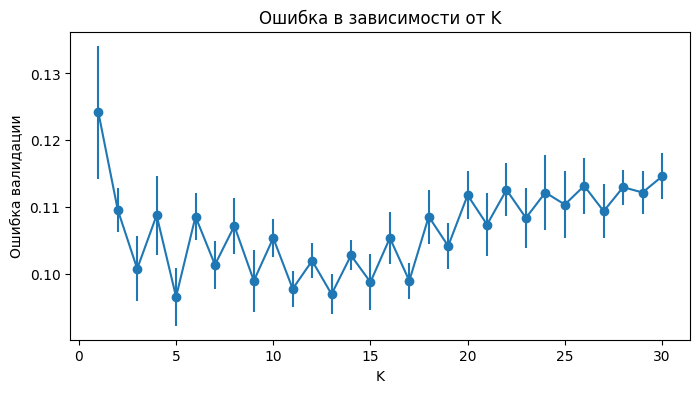

In [ ]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

k_values = range(1, 31)
mean_acc = []
std_acc = []

for k in k_values:
    scores = []
    for train_idx, val_idx in skf.split(X_scaled, y_all):
        knn = KNeighborsClassifier(n_neighbors=k)
        knn.fit(X_scaled[train_idx], y_all.values[train_idx])
        scores.append(knn.score(X_scaled[val_idx], y_all.values[val_idx]))
    mean_acc.append(np.mean(scores))
    std_acc.append(np.std(scores))

mean_acc = np.array(mean_acc)
std_acc = np.array(std_acc)

best_k = list(k_values)[mean_acc.argmax()]
print('Оптимальное K:', best_k)
print('Средняя точность:', round(mean_acc.max(), 4), '+-', round(std_acc[mean_acc.argmax()], 4))

plt.figure(figsize=(8, 4))
plt.errorbar(list(k_values), 1 - mean_acc, yerr=std_acc, marker='o')
plt.xlabel('K')
plt.ylabel('Ошибка валидации')
plt.title('Ошибка в зависимости от K')
plt.show()

**Объяснение:** Кросс-валидация делит данные на 5 частей, и каждая по очереди становится проверочной, поэтому оценка не зависит от одного случайного разделения. `StratifiedKFold` сохраняет долю ушедших клиентов в каждой части. Лучший результат при K=5 (точность около 0.903). При малых K модель переобучается (реагирует на шум), при больших недообучается (слишком сглаживает), поэтому оптимум находится посередине.

### Упражнение 8: Работа с несбалансированными классами (Class Imbalance)
В наборе данных Orange Telecom мажоритарный класс представляют клиенты, которые не ушли (`churned = False`), а ушедшие — меньшинство. Объясните, почему метрика `accuracy` (точность) в данном контексте вводит в заблуждение. Измените код оценки для расчета матрицы ошибок (Confusion Matrix), Precision, Recall и F1-score с использованием `sklearn.metrics`.

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

print('Доля неушедших в тесте (accuracy тупой модели):', round(1 - y_test.mean(), 3))

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

print('Accuracy KNN:', round(np.mean(y_pred == y_test), 3))
print('Матрица ошибок:')
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Доля неушедших в тесте (accuracy тупой модели): 0.859
Accuracy KNN: 0.9
Матрица ошибок:
[[1264   24]
 [ 126   86]]
              precision    recall  f1-score   support

           0       0.91      0.98      0.94      1288
           1       0.78      0.41      0.53       212

    accuracy                           0.90      1500
   macro avg       0.85      0.69      0.74      1500
weighted avg       0.89      0.90      0.89      1500



**Объяснение:** Ушедших клиентов всего около 14%, поэтому модель, которая всегда отвечает «не уйдёт», получила бы accuracy около 0.86 и не нашла бы ни одного ушедшего. Наша модель с accuracy 0.90 выглядит хорошо, но по матрице ошибок видно, что из 212 ушедших клиентов она нашла только 86 (recall = 0.41), а 126 пропустила. Precision для класса «ушёл» 0.78, F1 = 0.53. Поэтому для несбалансированных данных нужно смотреть на precision, recall и F1, а не на accuracy.

### Упражнение 9: Влияние весов расстояния (`weights='distance'`) против равномерных весов
Сравните поведение модели KNN при `weights='uniform'` и `weights='distance'`. Напишите эксперимент на Python, оценивающий чувствительность модели к шуму (выбросам в пространстве признаков) для обоих типов весов. Какой вариант более уязвим к шуму и почему?

In [ ]:
rng = np.random.RandomState(0)

y_noisy = y_train.copy()
noise_idx = rng.choice(len(y_noisy), size=int(0.1 * len(y_noisy)), replace=False)
y_noisy[noise_idx] = 1 - y_noisy[noise_idx]

for w in ['uniform', 'distance']:
    for k in [3, 15]:
        knn_clean = KNeighborsClassifier(n_neighbors=k, weights=w).fit(X_train, y_train)
        knn_noisy = KNeighborsClassifier(n_neighbors=k, weights=w).fit(X_train, y_noisy)
        print(w, 'K =', k,
              '| без шума:', round(knn_clean.score(X_test, y_test), 3),
              '| с шумом:', round(knn_noisy.score(X_test, y_test), 3))

uniform K = 3 | без шума: 0.904 | с шумом: 0.883
uniform K = 15 | без шума: 0.904 | с шумом: 0.897
distance K = 3 | без шума: 0.904 | с шумом: 0.883
distance K = 15 | без шума: 0.905 | с шумом: 0.898


**Объяснение:** В эксперименте у 10% обучающих клиентов перевернули метки (это шум). При `uniform` все соседи голосуют одинаково, при `distance` голос ближних соседей весит больше. В этом наборе данных разница между вариантами получилась очень маленькой: шум снижает точность при K=3 (0.904 до 0.883) и почти не влияет при K=15 (0.904 до 0.897). Главный вывод: сильнее всего шум влияет при малом K. По теории `distance` более уязвим к шуму, потому что зашумлённая точка, оказавшаяся очень близко, получает огромный вес и перетягивает ответ. `uniform` сглаживает такие случаи, особенно при большом K. В нашем эксперименте это различие не проявилось.

### Упражнение 10: Проклятие размерности (Curse of Dimensionality)
Алгоритм KNN основан на измерении расстояний в многомерных пространствах. С ростом числа признаков объем пространства растет экспоненциально, и точки становятся равноудаленными. Напишите небольшой кейс или эксперимент на Python, показывающий, как искусственное увеличение размерности (добавление колонок случайного шума к данным churn) ухудшает производительность классификатора KNN.

Колонок шума: 0 | точность: 0.9
Колонок шума: 10 | точность: 0.866
Колонок шума: 50 | точность: 0.847
Колонок шума: 100 | точность: 0.854
Колонок шума: 300 | точность: 0.847


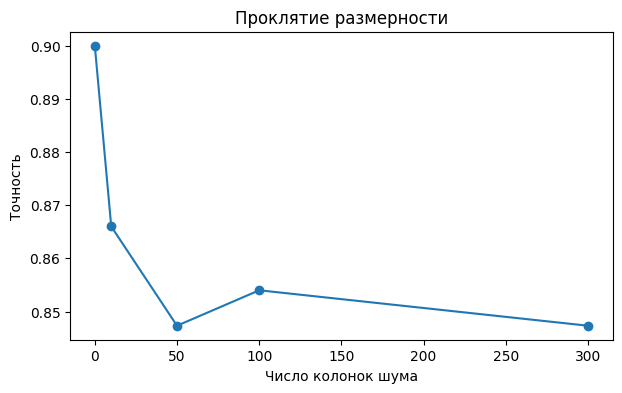

In [ ]:
noise_counts = [0, 10, 50, 100, 300]
scores = []

for n in noise_counts:
    noise = np.random.RandomState(1).rand(len(X_scaled), n)
    X_noise = np.hstack([X_scaled, noise])

    X_tr, X_te, y_tr, y_te = train_test_split(
        X_noise, y_all.values, test_size=0.3, random_state=42, stratify=y_all)

    knn = KNeighborsClassifier(n_neighbors=5)
    knn.fit(X_tr, y_tr)
    acc = knn.score(X_te, y_te)
    scores.append(acc)
    print('Колонок шума:', n, '| точность:', round(acc, 3))

plt.figure(figsize=(7, 4))
plt.plot(noise_counts, scores, marker='o')
plt.xlabel('Число колонок шума')
plt.ylabel('Точность')
plt.title('Проклятие размерности')
plt.show()

**Объяснение:** К 17 настоящим признакам добавляли колонки случайного шума. Точность упала с 0.900 (без шума) до примерно 0.85 уже при 50 лишних колонках и дальше не выросла. Причина: все колонки входят в евклидово расстояние одинаково, лишние случайные признаки добавляют в расстояние шум, и «ближайшие» соседи перестают быть по-настоящему похожими. В пространстве с большим числом признаков точки становятся почти равноудалёнными. Помогает отбор признаков или уменьшение размерности.

### Упражнение 11: KNN для регрессии против классификации
Хотя в ноутбуке мы использовали `KNeighborsClassifier` для задачи бинарной классификации, KNN также применим для регрессии (`KNeighborsRegressor`). Напишите скрипт, применяющий `KNeighborsRegressor` для предсказания непрерывной переменной (например, `total_day_charges` на основе минут и звонков). Сравните функцию потерь (MSE — Mean Squared Error) для различных значений K.

K = 1 | MSE = 0.846
K = 3 | MSE = 0.6983
K = 5 | MSE = 0.4697
K = 10 | MSE = 0.559
K = 20 | MSE = 0.715
K = 50 | MSE = 1.2791


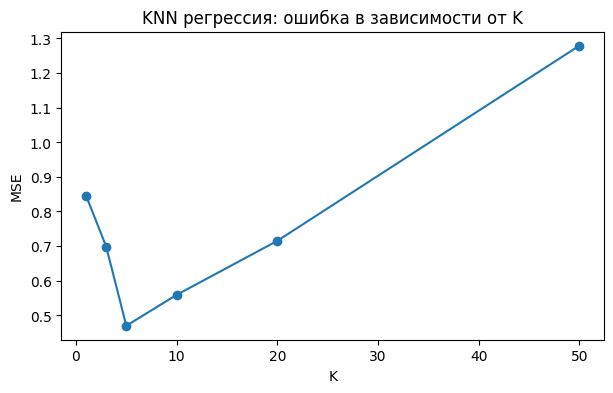

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error

X_reg = df[['total_day_minutes', 'total_day_calls']]
y_reg = df['total_day_charge']

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.3, random_state=42)

scaler = MinMaxScaler().fit(Xr_train)
Xr_train = scaler.transform(Xr_train)
Xr_test = scaler.transform(Xr_test)

mse_list = []
k_list = [1, 3, 5, 10, 20, 50]
for k in k_list:
    reg = KNeighborsRegressor(n_neighbors=k)
    reg.fit(Xr_train, yr_train)
    mse = mean_squared_error(yr_test, reg.predict(Xr_test))
    mse_list.append(mse)
    print('K =', k, '| MSE =', round(mse, 4))

plt.figure(figsize=(7, 4))
plt.plot(k_list, mse_list, marker='o')
plt.xlabel('K')
plt.ylabel('MSE')
plt.title('KNN регрессия: ошибка в зависимости от K')
plt.show()

**Объяснение:** `KNeighborsRegressor` предсказывает не класс, а среднее значение целевой переменной у K ближайших соседей. Минимальная ошибка (MSE около 0.47) получилась при K=5. При K=1 модель переобучается (MSE 0.85), при K=50 слишком сглаживает (MSE 1.28). Заметка: `total_day_charge` почти линейно зависит от `total_day_minutes`, поэтому задача лёгкая.

### Упражнение 12: Пайплайны машинного обучения с `Pipeline` и `GridSearchCV`
Постройте полный пайплайн в Scikit-learn, включающий: (1) `MinMaxScaler`, (2) опционально селектор признаков (`SelectKBest`) и (3) `KNeighborsClassifier`. Используйте `GridSearchCV` для одновременного поиска оптимальных гиперпараметров: количества соседей K in {3, 5, 7, 9, 11}, типа весов (`uniform`, `distance`) и метрики расстояния (p=1 или p=2). Выведите лучший набор гиперпараметров и оценку на тестовой выборке.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.feature_selection import SelectKBest

pipe = Pipeline([
    ('scaler', MinMaxScaler()),
    ('select', SelectKBest()),
    ('knn', KNeighborsClassifier())
])

params = {
    'select__k': [8, 'all'],
    'knn__n_neighbors': [3, 5, 7, 9, 11],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2]
}

Xp_train, Xp_test, yp_train, yp_test = train_test_split(
    X_all, y_all, test_size=0.3, random_state=42, stratify=y_all)

grid = GridSearchCV(pipe, params, cv=5)
grid.fit(Xp_train, yp_train)

print('Лучшие параметры:', grid.best_params_)
print('Лучшая точность на кросс-валидации:', round(grid.best_score_, 4))
print('Точность на тестовой выборке:', round(grid.score(Xp_test, yp_test), 4))

Лучшие параметры: {'knn__n_neighbors': 7, 'knn__p': 1, 'knn__weights': 'uniform', 'select__k': 8}
Лучшая точность на кросс-валидации: 0.908
Точность на тестовой выборке: 0.9027


**Объяснение:** Pipeline соединяет масштабирование, отбор признаков и KNN в одну модель, а `GridSearchCV` перебирает все комбинации параметров с кросс-валидацией. Благодаря Pipeline масштабирование обучается только на обучающей части каждого фолда, поэтому нет утечки данных. Лучшие параметры: 7 соседей, p=1 (манхэттенское расстояние), равные веса, 8 лучших признаков. Точность на кросс-валидации 0.908, на тестовой выборке 0.903.